# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [2]:
TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)

    #терми для всіх змінних
    for var in (x, y, z):
        var.automf(3, names=TERMS)

    #правила відповідно до таблиці
    rules = [
        ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
        for i in range(3) for j in range(3)
    ]

    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [3]:
#межі змінних згідно з варіантом 4
range_11 = ((0, 50), (1, 10), (0, 10))
range_12 = ((0, 10), (0, 10), (0, 10))
range_13 = ((0, 10), (0, 10), (0, 100))

#таблиця правил (1.1: ефективність інвестицій)
table_11 = [
    ["середній", "низький", "низький"],
    ["високий", "середній", "низький"],
    ["високий", "високий", "середній"]
]
#(1.2: якість виконаних робіт)
table_12 = [
    ["низький", "низький", "середній"],
    ["низький", "середній", "високий"],
    ["середній", "високий", "високий"]
]
#(1.3: ефективність проекту)
table_13 = [row[:] for row in table_12]

#отримання результату
def get_output(sim, x_value, y_value):
    sim.input["x"] = x_value
    sim.input["y"] = y_value
    sim.compute()
    return float(sim.output["z"])

#підсистеми 1.1 і 1.2
sim_11 = fuzzy_system(*range_11, table_11, "centroid")
sim_12 = fuzzy_system(*range_12, table_12, "centroid")
out_11 = get_output(sim_11, 45, 7.3)
out_12 = get_output(sim_12, 9.5, 9.5)

#підсистема 1.3: два методи дефазифікації
sim_13_centroid = fuzzy_system(*range_13, table_13, "centroid")
sim_13_mom = fuzzy_system(*range_13, table_13, "mom")
out_13_centroid = get_output(sim_13_centroid, out_11, out_12)
out_13_mom = get_output(sim_13_mom, out_11, out_12)

print(f"1.1: ефективність інвестицій: {out_11:.4f} бала")
print(f"\n1.2: якість виконаних робіт: {out_12:.4f} бала")
print(f"\n1.3: ефективність проекту:")
print(f"    метод центроїда: {out_13_centroid:.4f} %")
print(f"    метод середнього максимумів: {out_13_mom:.4f} %")

1.1: ефективність інвестицій: 5.7460 бала

1.2: якість виконаних робіт: 7.3824 бала

1.3: ефективність проекту:
    метод центроїда: 55.3858 %
    метод середнього максимумів: 50.0000 %


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [4]:
def memberships(value, bounds):
    a, b = bounds
    m = (a + b) / 2
    universe = np.linspace(a, b, 201)
    triangles = [[a, a, m], [a, m, b], [m, b, b]]
    return {term: float(fuzz.interp_membership(universe, fuzz.trimf(universe, tri), value)) for term, tri in zip(TERMS, triangles)}

mu_x = memberships(out_11, range_13[0])
mu_y = memberships(out_12, range_13[1])

rule_strengths = [
    (TERMS[i], TERMS[j], table_13[i][j],
     min(mu_x[TERMS[i]], mu_y[TERMS[j]]))
    for i in range(3) for j in range(3)
]
rule_strengths.sort(key=lambda rule: rule[3], reverse=True)

print("Сили правил підсистеми 1.3 (від найбільшої до найменшої):")
print(f"{'№':<4}{'x (ефектив. інвестицій)':<27}{'y (якість робіт)':<20}{'z (ефектив. проекту)':<20}{'сила':>7}")
for number, (x_term, y_term, z_term, strength) in enumerate(rule_strengths, 1):
    print(f"{number:<4}{x_term:<27}{y_term:<20}{z_term:<20}{strength:>7.4f}")

Сили правил підсистеми 1.3 (від найбільшої до найменшої):
№   x (ефектив. інвестицій)    y (якість робіт)    z (ефектив. проекту)   сила
1   середній                   середній            середній             0.5235
2   середній                   високий             високий              0.4765
3   високий                    середній            високий              0.1492
4   високий                    високий             високий              0.1492
5   низький                    низький             низький              0.0000
6   низький                    середній            низький              0.0000
7   низький                    високий             середній             0.0000
8   середній                   низький             низький              0.0000
9   високий                    низький             середній             0.0000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

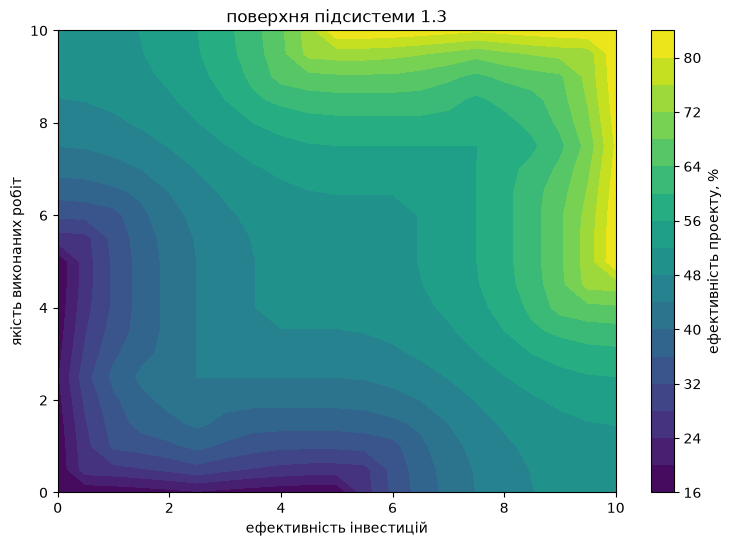

In [7]:
def plot_surface(table, title):
    sim = fuzzy_system(*range_13, table, "centroid")
    xs = np.linspace(*range_13[0], 21)
    ys = np.linspace(*range_13[1], 21)
    Z = np.zeros((21, 21))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            Z[i, j] = get_output(sim, x, y)

    plt.figure(figsize=(9, 6))
    contour = plt.contourf(xs, ys, Z, levels=20, cmap="viridis")
    plt.colorbar(contour, label="ефективність проекту, %")
    plt.xlabel("ефективність інвестицій")
    plt.ylabel("якість виконаних робіт")
    plt.title(title)
    plt.show()

plot_surface(table_13, "поверхня підсистеми 1.3")

### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

порівняння результатів підсистеми 1.3:
метод                          до зміни     після зміни
центроїд                        55.3858         80.7706
середнє максимумів              50.0000         88.0036


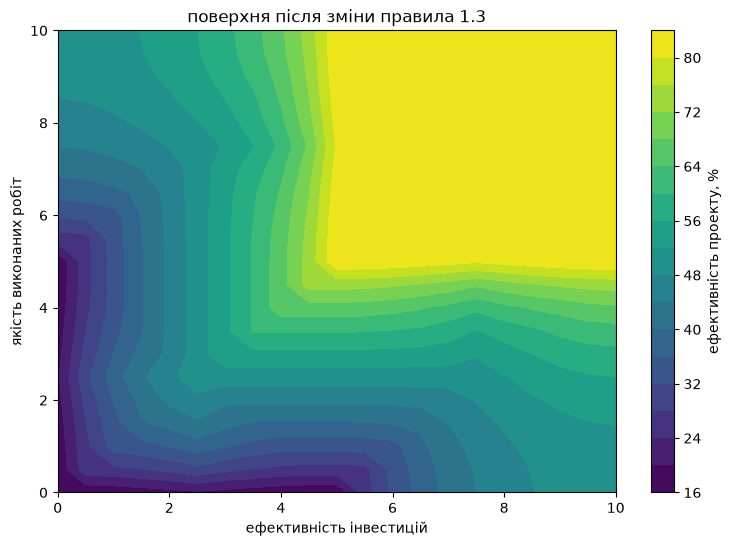

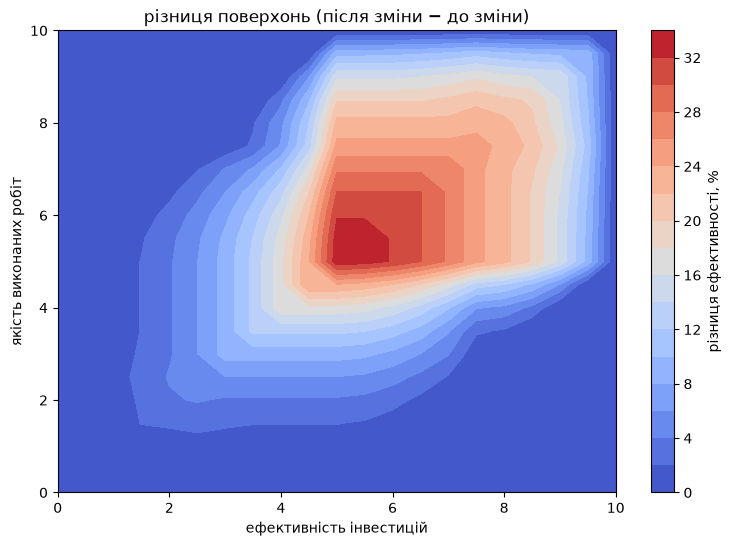

In [9]:
#копія початкової таблиці та зміна одного правила
old_table_13 = [row[:] for row in table_13]
new_table_13 = [row[:] for row in table_13]
new_table_13[1][1] = "високий" #рядок «середній», стовпець «середній» — «середній» замінити на «високий»

#обчислення результатів у тій самій точці
sim_new_centroid = fuzzy_system(*range_13, new_table_13, "centroid")
sim_new_mom = fuzzy_system(*range_13, new_table_13, "mom")
new_centroid = get_output(sim_new_centroid, out_11, out_12)
new_mom = get_output(sim_new_mom, out_11, out_12)

print("порівняння результатів підсистеми 1.3:")
print(f"{'метод':<25}{'до зміни':>14}{'після зміни':>16}")
print(f"{'центроїд':<25}{out_13_centroid:>14.4f}{new_centroid:>16.4f}")
print(f"{'середнє максимумів':<25}{out_13_mom:>14.4f}{new_mom:>16.4f}")

#обчислення поверхні
def calculate_surface(table):
    sim = fuzzy_system(*range_13, table, "centroid")
    xs = np.linspace(*range_13[0], 21)
    ys = np.linspace(*range_13[1], 21)
    Z = np.zeros((21, 21))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            Z[i, j] = get_output(sim, x, y)
    return xs, ys, Z

#початкова та змінена поверхні
xs, ys, Z_old = calculate_surface(old_table_13)
_, _, Z_new = calculate_surface(new_table_13)

# різниця поверхонь
Z_diff = Z_new - Z_old

#побудова поверхні після зміни правила
plt.figure(figsize=(9, 6))
plt.contourf(xs, ys, Z_new, levels=20, cmap="viridis")
plt.colorbar(label="ефективність проекту, %")
plt.xlabel("ефективність інвестицій")
plt.ylabel("якість виконаних робіт")
plt.title("поверхня після зміни правила 1.3")
plt.show()

#побудова різниці поверхонь
plt.figure(figsize=(9, 6))
plt.contourf(xs, ys, Z_diff, levels=20, cmap="coolwarm")
plt.colorbar(label="різниця ефективності, %")
plt.xlabel("ефективність інвестицій")
plt.ylabel("якість виконаних робіт")
plt.title("різниця поверхонь (після зміни − до зміни)")
plt.show()

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [10]:
sample = pd.read_csv("4/sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

#поділ: навчальна та тестова вибірка
X_tr, X_te, y_tr, y_te = train_test_split(
    X.to_numpy(), y.to_numpy(),
    test_size=0.25, random_state=0
)

#нормалізація даних
x_min = X_tr.min(axis=0)
x_span = X_tr.max(axis=0) - x_min
x_tr = (X_tr - x_min) / x_span
x_te = (X_te - x_min) / x_span

y_min = y_tr.min()
y_span = y_tr.max() - y_min
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

#похибка прогнозу середнім значенням навчальної вибірки
mean_value = y_tr.mean()
rmse_train = np.sqrt(np.mean((y_tr - mean_value) ** 2))
rmse_test = np.sqrt(np.mean((y_te - mean_value) ** 2))

print("розміри вибірок:")
print(f"навчальна: х = {x_tr.shape}, y = {t_tr.shape}")
print(f"тестова:   х = {x_te.shape}, y = {t_te.shape}")
print("\nRMSE прогнозу середнім:")
print(f"навчальна: {rmse_train:.4f}")
print(f"тестова:   {rmse_test:.4f}")

розміри вибірок:
навчальна: х = (30, 4), y = (30,)
тестова:   х = (11, 4), y = (11,)

RMSE прогнозу середнім:
навчальна: 1.0483
тестова:   0.9513


In [11]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [12]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [13]:
data = np.column_stack([x_tr, t_tr])

for ra in [0.3, 0.5, 0.8]:
    centers = subclust(data, ra)
    print(f"ra = {ra}: кількість правил = {len(centers)}")

ra = 0.3: кількість правил = 18
ra = 0.5: кількість правил = 7
ra = 0.8: кількість правил = 3


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [14]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    #ширина правила k на кожен вхід
    widths = np.sqrt(np.array([((u[k] ** 2) @ ((x_tr - centers[k]) ** 2)) / (u[k] ** 2).sum()
        for k in range(c)]))
    return pack(centers, np.clip(widths, 0.08, 0.8))

#побудова та налаштування трьох правил
theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

#обчислення RMSE
baseline_train = rmse_train
baseline_test = rmse_test
before_train, before_test = errors(theta, 3)
after_train, after_test = errors(theta_tuned, 3)

results = pd.DataFrame({
    "модель": ["прогноз середнім", "до налаштування", "після налаштування"],
    "RMSE навчальна": [baseline_train, before_train, after_train],
    "RMSE тестова": [baseline_test, before_test, after_test]
})

print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

            модель  RMSE навчальна  RMSE тестова
  прогноз середнім          1.0483        0.9513
   до налаштування          0.9514        1.0634
після налаштування          0.8292        1.2878


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

 кількість правил  RMSE навчальна  RMSE тестова
                2          0.9042        1.1402
                3          0.8292        1.2878
                4          0.7964        1.1178
                5          0.4378        1.0597
                6          0.4388        1.0134


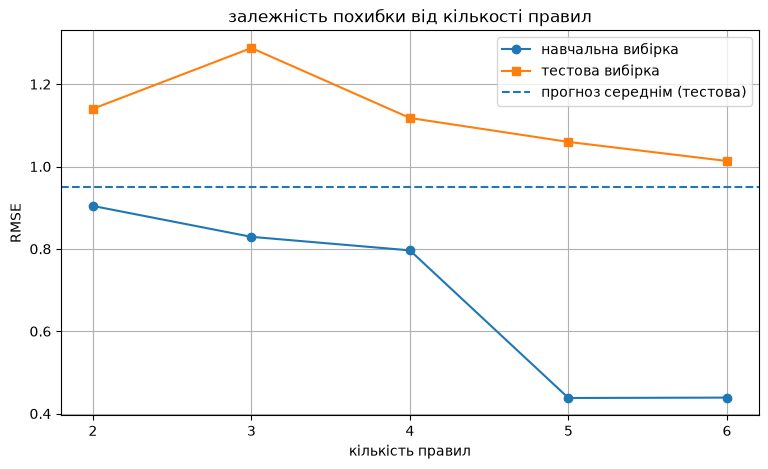

In [15]:
#перевірка різної кількості правил
rule_counts = range(2, 7)
train_errors = []
test_errors = []

for c in rule_counts:
    current_theta = cmeans_rules(c)
    tuned_theta = tune(current_theta, c)
    train_rmse, test_rmse = errors(tuned_theta, c)
    train_errors.append(train_rmse)
    test_errors.append(test_rmse)

results = pd.DataFrame({
    "кількість правил": list(rule_counts),
    "RMSE навчальна": train_errors,
    "RMSE тестова": test_errors
})
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

#графік похибок
plt.figure(figsize=(9, 5))
plt.plot(rule_counts, train_errors, marker="o", label="навчальна вибірка")
plt.plot(rule_counts, test_errors, marker="s", label="тестова вибірка")
plt.axhline(rmse_test, linestyle="--", label="прогноз середнім (тестова)")
plt.xlabel("кількість правил")
plt.ylabel("RMSE")
plt.title("залежність похибки від кількості правил")
plt.xticks(list(rule_counts))
plt.grid(True)
plt.legend()
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [16]:
#фонди часу бригад і дільник
FUND = np.array([7, 6, 5])
TIME_DIV = 8

#час обслуговування та втрати для всіх об'єктів
t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample.iloc[:, -1].to_numpy()

print(f"об'єктів: {len(t)}, загальний фонд часу: {sum(FUND)} год")

об'єктів: 41, загальний фонд часу: 18 год


In [17]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [19]:
plan_greedy = np.zeros(len(t), dtype=int)
used = np.zeros(3)
order = np.argsort(-(v / t))
for i in order:
    for brigade in range(3):
        if used[brigade] + t[i] <= FUND[brigade]:
            plan_greedy[i] = brigade + 1
            used[brigade] += t[i]
            break

print(f"сума уникнутих втрат: {value(plan_greedy):.3f} тис. грн")
print("завантаження бригад:", load(plan_greedy))
print("перевищення фондів:", overflow(plan_greedy))

сума уникнутих втрат: 24.963 тис. грн
завантаження бригад: [6.499875, 5.9775, 4.725375]
перевищення фондів: 0.0


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [20]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


#plan_repair
ga_candidate = repair(run_ga(
    lambda ga, sol, idx: value(repair(sol))
))
plan_repair = ga_candidate if value(ga_candidate) >= value(plan_greedy) else plan_greedy.copy()

print(f"ГА з ремонтом: сума={value(plan_repair):.4f} тис. грн")
print("Завантаження бригад:", [round(x, 4) for x in load(plan_repair)])
print("Перевищення:", overflow(plan_repair))

ГА з ремонтом: сума=25.0600 тис. грн
Завантаження бригад: [6.9041, 5.9084, 4.7275]
Перевищення: 0.0


In [21]:
#plan_penalty
plan_penalty = run_ga(
    lambda ga, sol, idx: value(sol) - 10 * overflow(sol)
)

print(f"ГА зі штрафом: сума={value(plan_penalty):.4f} тис. грн")
print("Завантаження бригад:", [round(x, 4) for x in load(plan_penalty)])
print("Перевищення:", overflow(plan_penalty))

ГА зі штрафом: сума=22.3890 тис. грн
Завантаження бригад: [6.1136, 5.5614, 4.6421]
Перевищення: 0.0


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [22]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [26]:
#plan_optimum і таблиця чотирьох планів
plan_optimum = optimum()
opt_value = value(plan_optimum)
plans = {
    "жадібний алгоритм": plan_greedy,
    "ГА з ремонтом": plan_repair,
    "ГА зі штрафом": plan_penalty,
    "оптимум": plan_optimum
}

results = []
for name, plan in plans.items():
    total = value(plan)
    results.append({
        "алгоритм": name,
        "сума втрат, тис. грн": round(total, 4),
        "завантаження бригад": [round(x, 4) for x in load(plan)],
        "перевищення, год": round(overflow(plan), 4),
        "% від оптимуму": round(total / opt_value * 100, 2)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

         алгоритм  сума втрат, тис. грн      завантаження бригад  перевищення, год  % від оптимуму
жадібний алгоритм                24.963 [6.4999, 5.9775, 4.7254]               0.0           99.11
    ГА з ремонтом                25.060 [6.9041, 5.9084, 4.7275]               0.0           99.50
    ГА зі штрафом                22.389 [6.1136, 5.5614, 4.6421]               0.0           88.89
          оптимум                25.186  [6.9561, 5.9775, 4.997]               0.0          100.00


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [27]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 25.06 з оптимуму 25.186
